In [1]:
import numpy as np
import sionna as sn
import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import Layer, Dense
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import os

2026-09-11 22:02:47.071826: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1789153367.083908   23473 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1789153367.088052   23473 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1789153367.097517   23473 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1789153367.097530   23473 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1789153367.097532   23473 computation_placer.cc:177] computation placer alr

In [2]:
class Modulator(Layer):

    def __init__(self, constellation, N,  parity_k, **kwargs):
        super(Modulator, self).__init__(**kwargs)

        # Define the real and imaginary parts of the constellation as trainable variables
        # self.constellation_real = tf.Variable(constellation.real, dtype=tf.float32, trainable=True)
        # self.constellation_imag = tf.Variable(constellation.imag, dtype=tf.float32, trainable=True)
        self.constellation_real_init = constellation.real
        self.constellation_imag_init = constellation.imag
        self.parity_k = parity_k
        self.N = N

    def build(self, input_shape):
        self.constellation_real = self.add_weight(
            name="constellation_real",
            shape=self.constellation_real_init.shape,
            initializer=tf.constant_initializer(self.constellation_real_init),
            trainable=True
        )
        self.constellation_imag = self.add_weight(
            name="constellation_imag",
            shape=self.constellation_imag_init.shape,
            initializer=tf.constant_initializer(self.constellation_imag_init),
            trainable=True
        )

    def call(self, s, probabilities):
        # Combine the real and imaginary parts into a complex-valued constellation
        constellation_combined = tf.complex(self.constellation_real, self.constellation_imag)

        # Expand the signal dimension to align for matrix multiplication
        s = tf.expand_dims(s, axis=-1)

        # Normalize the constellation
        normalization_constants = tf.sqrt(
            tf.reduce_sum(tf.reshape((2**self.parity_k)*probabilities * tf.abs(constellation_combined) ** 2,(1,(2**self.parity_k),int(self.N/(2**self.parity_k)))), 2)
        )
        normalization_constants = tf.expand_dims(normalization_constants, axis=2)
        normalization_constants = tf.complex(tf.reshape(tf.tile(normalization_constants,(1,1,int(self.N/(2**self.parity_k)))),(1,self.N)),0.0)
        norm_constellation = constellation_combined / normalization_constants

        # print('norm_constellation',norm_constellation.shape)
        # print('s',s.shape)
        # Compute the modulated signal
        x_real = tf.matmul(tf.math.real(norm_constellation), s)
        x_imag = tf.matmul(tf.math.imag(norm_constellation), s)
        x = tf.complex(x_real, x_imag)

        return tf.squeeze(x, axis=[-1, -2]), norm_constellation

In [3]:
def entropy(pdf, base=2):
    pdf = np.asarray(pdf, dtype=np.float64)
    pdf = pdf[pdf > 0]  # remove zero entries to avoid log(0)
    pdf /= np.sum(pdf)  # normalize to ensure valid probability distribution

    h = -np.sum(pdf * np.log(pdf) / np.log(base))
    return h


In [4]:
batch_size = 10
papr_batch_size = 30
block_size = 4096-32*4

N = 64  # Number of classes (symbols)
# bits_per_symbol = int(np.log2(N))
parity_k = 0

self_upsampler = sn.phy.signal.Upsampling(samples_per_symbol=4)
self_tx_filter = sn.phy.signal.RootRaisedCosineFilter(beta=0.3,
                                                 samples_per_symbol=4,
                                                 span_in_symbols=32)

I0000 00:00:1789153373.080985   23473 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5544 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050, pci bus id: 0000:01:00.0, compute capability: 8.6


In [5]:
# no_constraint_pn_data = np.load('../Experiments_April/no_constraint_pn.npz')
#
# pmf = no_constraint_pn_data['constellation_probabilities']
# points = no_constraint_pn_data['constellation_points']
#
# self_modulator = Modulator(points,N,parity_k)


In [6]:
# print(entropy(pmf))

In [10]:


local_fonts_path = os.path.expanduser('~/.local/share/fonts')
fm.fontManager.addfont(os.path.join(local_fonts_path, 'times.ttf'))

plt.rcParams.update({
    "font.size": 12,
    "grid.linestyle": "--",
    "axes.grid": True
})

plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['mathtext.fontset'] = 'stix'

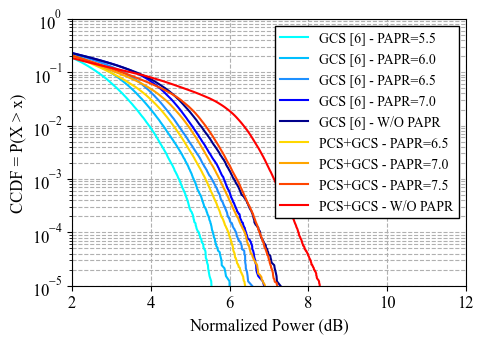

In [18]:
########### GCS only case

RESULTS_DIR = "../Experiments_April/results_gcs_benchmark"
snr_list = [13]
papr_list = [5.5, 6.0, 6.5, 7.0]

colors = ['cyan', 'deepskyblue', 'dodgerblue', 'blue']
color_index = 0

for snr_db in snr_list:
    plt.figure(figsize=(5.0, 3.6))
    for papr_db in papr_list:
        exp_name = f"snr_{snr_db}_papr_{papr_db}"
        data = np.load(f"{RESULTS_DIR}/{exp_name}.npz")

        x = data["ccdf_x_db"]
        y = data["ccdf_y"]

        plt.plot(x, y, label=f"GCS [6] - PAPR={papr_db}", color = colors[color_index])

        color_index = color_index + 1

data = np.load(f"no_constraint_gcs.npz")

x = data["ccdf_x_db"]
y = data["ccdf_y"]

plt.plot(x, y, label=f"GCS [6] - W/O PAPR", color = 'darkblue')



########### PCS + GCS only case

RESULTS_DIR = "../Experiments_August/results_64_pn_120Hz_lowpn"

snr_list = [13]
papr_list =  [6.5,  7.0,  7.5, "No PAPR"]
colors = ['gold', 'orange', 'orangered', 'red']
color_index = 0
parity_k = 0
papr_batch_size = 100

N = 64  # Number of classes (symbols)
bits_per_symbol = int(np.log2(N))

for snr_db in snr_list:



    for papr_db in papr_list:



        exp_name = f"snr_{snr_db}_papr_{papr_db}"
        data = np.load(f"{RESULTS_DIR}/{exp_name}.npz")

        # no_constraint_pn_data = np.load('no_constraint_pn.npz')

        pmf = data['constellation_probabilities']
        points = data['constellation_points']

        self_modulator = Modulator(points,N,parity_k)

        indices = tf.random.categorical(
            tf.math.log(pmf),  # shape (1, 64)
            num_samples=papr_batch_size * block_size
        )

        indices = tf.reshape(indices, [papr_batch_size, block_size])
        one_hot = tf.one_hot(indices, depth=64)
        x_power,_ = self_modulator(one_hot, pmf)
        x_up_power = self_upsampler(x_power)
        x_tx_filt_power = self_tx_filter(x_up_power)  # 'same' for discarding the edges
        p_x = tf.square(tf.abs(x_tx_filt_power))
        power_samples = p_x / tf.reduce_mean(p_x)

        powers = tf.reshape(power_samples, [-1])
        powers_db = 10 * tf.math.log(powers + 1e-12) / tf.math.log(10.)

        x_sorted = np.sort(powers_db.numpy())
        ccdf = 1.0 - np.arange(1, len(x_sorted) + 1) / len(x_sorted)

        # x = data["ccdf_x_db"]
        # y = data["ccdf_y"]

        if not papr_db == 'No PAPR':
            plt.plot(x_sorted, ccdf, label=f"PCS+GCS - PAPR={papr_db}", color = colors[color_index])
        else:
            plt.plot(x_sorted, ccdf, label=f"PCS+GCS - W/O PAPR", color = colors[color_index])

        color_index = color_index + 1

plt.yscale("log")
plt.xlabel("Normalized Power (dB)")
plt.ylabel("CCDF = P(X > x)")
# plt.title(f"CCDF")
plt.grid(True, which="both")
plt.xlim(2, 12.0)
plt.ylim(1e-5, 1)
plt.legend(loc = 'upper right',
           framealpha=1,
           edgecolor=(0, 0, 0, 0),
           frameon=True,
           fancybox=False,
           ncol=1,
           fontsize=10)
plt.tight_layout()
plt.savefig(f"ccdf_120_pcs_gcs.pdf")

In [2]:
import tensorflow as tf
print(tf.__version__)

2.19.0


In [3]:
import tensorflow_probability as tfp
print(tfp.__version__)


0.25.0
